# Exploratory data analysis

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

## Load the training data

In [2]:
DATA_DIR = Path("../data")

train_df = pd.read_json(DATA_DIR / "train.json")

print("Dataset shape:", train_df.shape)

train_df.head()

Dataset shape: (7401, 2)


,reviews,sentiments
0,I bought this belt for my daughter in-law for ...,1
1,The size was perfect and so was the color. It...,1
2,"Fits and feels good, esp. for doing a swim rac...",1
3,These socks are absolutely the best. I take pi...,1
4,Thank you so much for the speedy delivery they...,1


In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7401 entries, 0 to 7400
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   reviews     7401 non-null   str  
 1   sentiments  7401 non-null   int64
dtypes: int64(1), str(1)
memory usage: 2.2 MB


In [4]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

Missing values:
reviews       0
sentiments    0
dtype: int64

Duplicate rows: 216


## Class distribution

Number of samples per class:
sentiments
0    1082
1    6319
Name: count, dtype: int64

Percentage per class:
sentiments
0    14.62
1    85.38
Name: count, dtype: float64


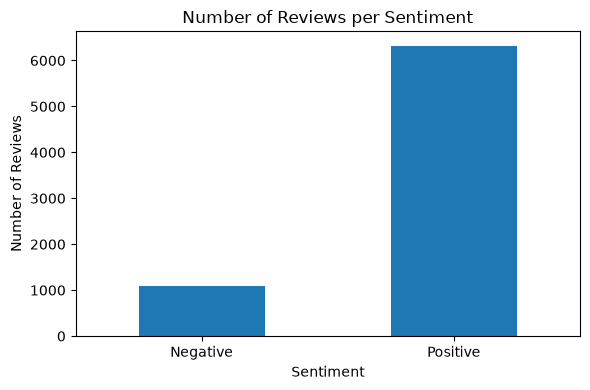

In [5]:
class_counts = train_df["sentiments"].value_counts().sort_index()

print("Number of samples per class:")
print(class_counts)

print("\nPercentage per class:")
print((class_counts / len(train_df) * 100).round(2))

class_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Number of Reviews per Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(
    ticks=[0, 1],
    labels=["Negative", "Positive"],
    rotation=0
)
plt.tight_layout()
plt.show()

## Length analysis

In [6]:
train_df["word_count"] = train_df["reviews"].apply(lambda x: len(str(x).split()))

train_df["character_count"] = train_df["reviews"].apply(
lambda x: len(str(x)))

train_df[["reviews", "word_count", "character_count"]].head()

,reviews,word_count,character_count
0,I bought this belt for my daughter in-law for ...,14,72
1,The size was perfect and so was the color. It...,19,88
2,"Fits and feels good, esp. for doing a swim rac...",74,415
3,These socks are absolutely the best. I take pi...,56,280
4,Thank you so much for the speedy delivery they...,44,234


In [7]:
train_df[["word_count", "character_count"]].describe().round(2)

,word_count,character_count
count,7401.00,7401.00
mean,56.68,300.93
std,53.34,285.24
min,4.00,24.00
25%,25.00,133.00
50%,42.00,223.00
75%,70.00,373.00
max,1066.00,5525.00


In [8]:
print(f"Average number of words: {train_df['word_count'].mean():.2f}")
print(f"Median number of words: {train_df['word_count'].median():.2f}")
print(f"Average number of characters: {train_df['character_count'].mean():.2f}")

Average number of words: 56.68
Median number of words: 42.00
Average number of characters: 300.93


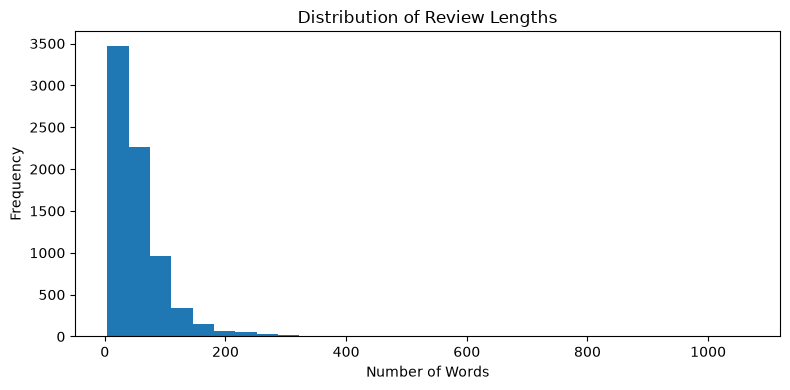

In [11]:
plt.figure(figsize=(8, 4))

plt.hist(
    train_df["word_count"],
    bins=30
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()